# 02 – SQL analysis

Runs every query in `sql/analysis.sql` against MySQL and shows the result, then draws the main charts.
The SQL file is the source of truth – this notebook only executes it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from db import get_engine, named_queries

pd.set_option("display.max_rows", 100)
engine = get_engine("olist")
queries = named_queries("../sql/analysis.sql")
results = {}
for name, sql in queries.items():
    results[name] = pd.read_sql(text(sql), engine)
    print(f"\n=== {name} ===")
    display(results[name])


=== Q0. Headline numbers ===


,delivered_orders,customers,revenue,freight,avg_order_value
0,96478,93358,13221498.0,2198276.0,137.04



=== Q1. Monthly revenue, orders and average order value ===


,month,revenue,orders,avg_order_value
0,2016-09,135.0,1,134.97
1,2016-10,40325.0,265,152.17
2,2016-12,11.0,1,10.90
3,2017-01,111798.0,750,149.06
4,2017-02,234223.0,1653,141.70
5,2017-03,359199.0,2546,141.08
6,2017-04,340670.0,2303,147.92
7,2017-05,489338.0,3546,138.00
8,2017-06,421923.0,3135,134.58
9,2017-07,481605.0,3872,124.38



=== Q2. Month-over-month growth (window function LAG) ===


,month,revenue,growth_pct
0,2017-01,111798.0,NaN
1,2017-02,234223.0,109.5
2,2017-03,359199.0,53.4
3,2017-04,340670.0,-5.2
4,2017-05,489338.0,43.6
5,2017-06,421923.0,-13.8
6,2017-07,481605.0,14.1
7,2017-08,554700.0,15.2
8,2017-09,607400.0,9.5
9,2017-10,648248.0,6.7


... (12 outputs left out)


=== Q9. Payment methods (share of payment value) ===


,payment_type,orders,pct_of_value,avg_installments
0,credit_card,74304,78.5,3.5
1,boleto,19191,18.0,1.0
2,voucher,3679,2.2,1.0
3,debit_card,1485,1.4,1.0



=== Q10. Delivery time and late % by customer state (slowest first) ===


,customer_state,orders,avg_delivery_days,pct_late
0,AM,145,26.4,4.1
1,AL,397,24.5,23.9
2,PA,946,23.7,12.4
3,MA,717,21.5,19.7
4,SE,335,21.5,15.2
5,CE,1279,21.2,15.3
6,PB,517,20.4,11.0
7,PI,476,19.4,16.0
8,BA,3256,19.3,14.0
9,RO,243,19.3,2.9


## Charts

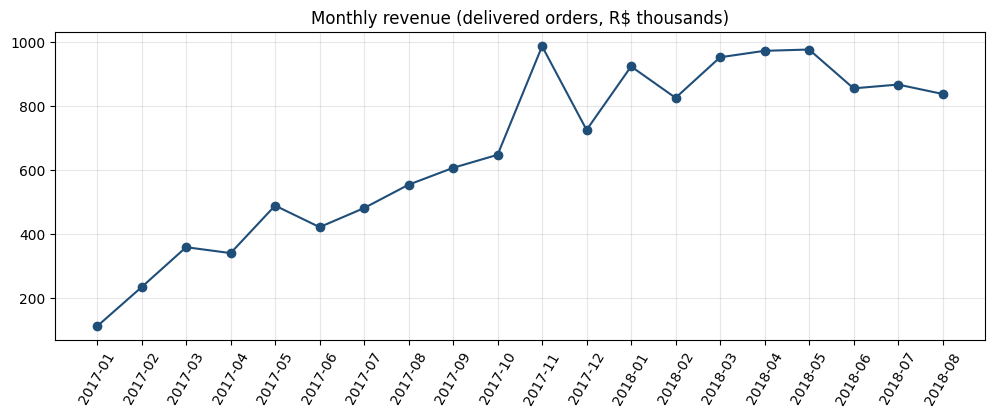

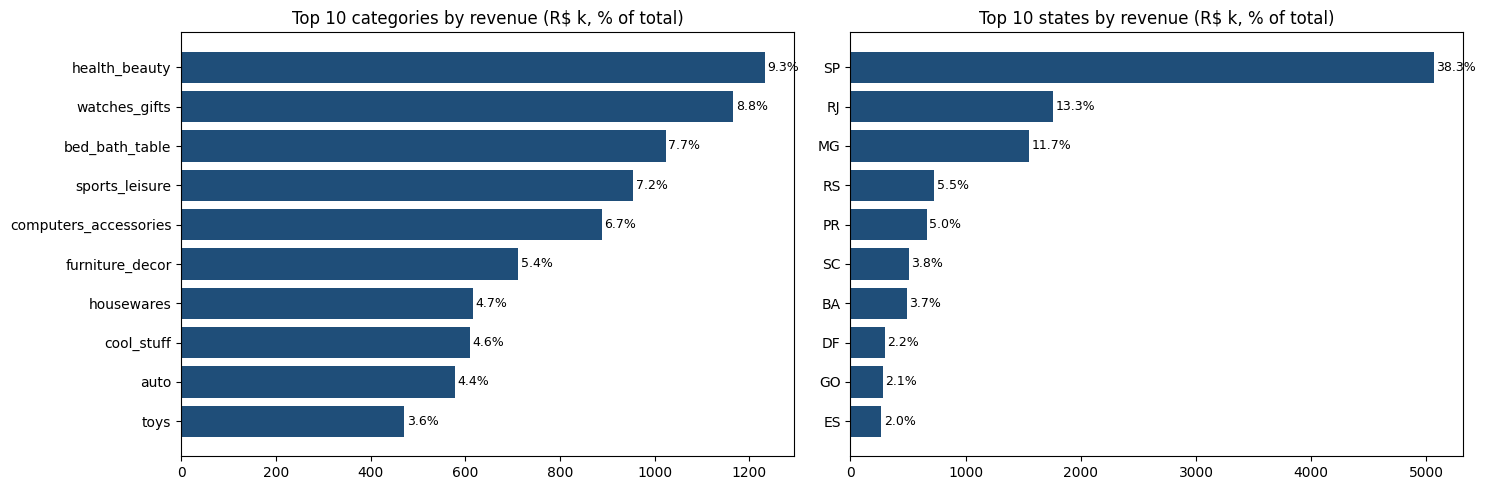

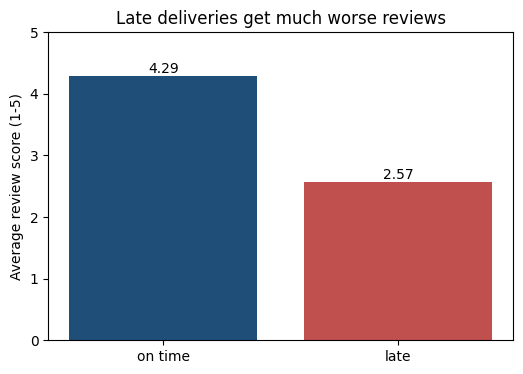

In [2]:
BLUE, RED = "#1f4e79", "#c0504d"
q = lambda prefix: next(v for k, v in results.items() if k.startswith(prefix + "."))

monthly = q("Q1")
monthly = monthly[(monthly.month >= "2017-01") & (monthly.month <= "2018-08")]   # full months only
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.month, monthly.revenue / 1000, marker="o", color=BLUE)
ax.set_title("Monthly revenue (delivered orders, R$ thousands)")
ax.tick_params(axis="x", rotation=60)
ax.grid(alpha=0.3)
plt.savefig("../dashboard/monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cat = q("Q3").sort_values("revenue")
axes[0].barh(cat.category, cat.revenue / 1000, color=BLUE)
for i, (v, p) in enumerate(zip(cat.revenue / 1000, cat.pct_of_total)):
    axes[0].text(v + 5, i, f"{p}%", va="center", fontsize=9)
axes[0].set_title("Top 10 categories by revenue (R$ k, % of total)")
st = q("Q4").head(10).sort_values("revenue")
axes[1].barh(st.customer_state, st.revenue / 1000, color=BLUE)
for i, (v, p) in enumerate(zip(st.revenue / 1000, st.pct_of_total)):
    axes[1].text(v + 20, i, f"{p}%", va="center", fontsize=9)
axes[1].set_title("Top 10 states by revenue (R$ k, % of total)")
plt.tight_layout()
plt.savefig("../dashboard/categories_states.png", dpi=150, bbox_inches="tight")
plt.show()

rev = q("Q6")
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(rev.delivery, rev.avg_review, color=[RED if d == "late" else BLUE for d in rev.delivery])
for i, v in enumerate(rev.avg_review):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_ylim(0, 5); ax.set_ylabel("Average review score (1-5)")
ax.set_title("Late deliveries get much worse reviews")
plt.savefig("../dashboard/late_vs_reviews.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

- **96,478 delivered orders** from **93,358 real customers** (`customer_unique_id`) generated **R$ 13.22M** in product revenue (+ R$ 2.20M freight). Average order value: **R$ 137**.
- **Growth:** revenue for Jan–Aug 2018 was **R$ 7.22M vs R$ 2.99M** for Jan–Aug 2017 (**+141%**). The single biggest month was **Nov 2017 (Black Friday): R$ 988k, +52% month-over-month**. Growth flattened in 2018 (May–Aug slightly down).
- **Categories:** health_beauty is #1 with **9.3%** of revenue, followed by watches_gifts (8.8%) and bed_bath_table (7.7%). The top 10 categories make up 62% of revenue – sales are spread out, no single category dominates.
- **Geography:** São Paulo (SP) alone brings **38.3%** of revenue; SP + RJ + MG together bring **63.3%**.
- **Delivery:** average **12.5 days**, **8.1%** of orders arrive late. Northern/north-eastern states wait much longer (AM 26.4 days, AL 24.5 days with 23.9% late) than SP (8.7 days, 5.9% late).
- **Late deliveries hurt reviews:** late orders average **2.57★** vs **4.29★** on time (−1.7 stars).
- **Repeat customers:** only **3.0%** of customers ordered more than once.
- **Payments:** credit card = **78.5%** of payment value (avg 3.5 instalments); boleto 18.0%.